# 📐 Notebook 1: Vectors, Matrices & Dot Products
### Fundamentals of Algebra for AI — Part 1 of 2


**Prerequisites:** Basic Python  
**Libraries:** NumPy (the standard for numerical computing in Python)

> *"The language of AI is linear algebra. Master it here."*

---
## 📋 Table of Contents
1. [Why Linear Algebra for AI?](#1)
2. [Vectors — Definition & Operations](#2)
3. [The Dot Product](#3)
4. [Matrices — Definition & Operations](#4)
5. [Matrix Multiplication](#5)
6. [Special Matrices](#6)
7. [Solving Linear Systems](#7)
8. [🤖 AI Application: Image as a Matrix](#8)


---
## 0. Setup — Import Libraries

We use **NumPy** throughout. It is the industry standard for matrix/vector math in Python.
`matplotlib` is used for visualizations.


In [1]:
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Pretty-print settings
np.set_printoptions(precision=3, suppress=True)
print("NumPy version:", np.__version__)
print("All libraries loaded ✅")

NumPy version: 2.4.6
All libraries loaded ✅


---
<a id='1'></a>
## 1. Why Linear Algebra for AI?

| Concept | Where it appears in AI |
|---|---|
| **Vector** | Word embeddings, feature vectors, pixel rows |
| **Matrix** | Dataset tables, weight matrices in neural nets |
| **Dot Product** | Similarity scores, neuron activation |
| **Matrix Multiply** | Passing data through neural network layers |
| **Eigenvalues** | PCA, dimensionality reduction, PageRank |

Every forward pass through a neural network is essentially:

$$\mathbf{output} = \text{activation}(\mathbf{W} \cdot \mathbf{x} + \mathbf{b})$$

where **W** is a weight *matrix*, **x** is an input *vector*, and **b** is a bias *vector*.


---
<a id='2'></a>
## 2. Vectors

A **vector** is an ordered list of numbers. Think of it as a point (or arrow) in space.

- A 2D vector: $\mathbf{v} = [3, 4]$ → a point in the xy-plane  
- A 3D vector: $\mathbf{v} = [5, 2, 3]$ → a point in xyz-space  
- In AI, a feature vector might have *thousands* of dimensions!

### Key properties:
- **Magnitude (length) AKA Norm:** $\|\mathbf{v}\| = \sqrt{v_1^2 + v_2^2 + \cdots + v_n^2}$
- **Direction:** the angle the arrow points


In [3]:
# ── Creating vectors in NumPy 
v = np.array([3, 4])          # 2D vector
w = np.array([1, -2])

print("v =", v)
print("w =", w)

v = [3 4]
w = [ 1 -2]


In [4]:
# Magnitude (L2 norm)
print("‖v‖ =", np.linalg.norm(v))   # should be 5 (3-4-5 triangle)
print("‖w‖ =", np.linalg.norm(w))

# Unit vector (direction only, magnitude = 1)
v_unit = v / np.linalg.norm(v)
print("\nUnit vector of v:", v_unit)
print("‖unit‖ =", np.linalg.norm(v_unit))   # always 1


‖v‖ = 5.0
‖w‖ = 2.23606797749979

Unit vector of v: [0.6 0.8]
‖unit‖ = 1.0


In [6]:
# ── Vector Arithmetic 
print("v=", v)
print("w=", w)
print("Addition  v + w =", v + w)     # element-wise
print("Subtract  v - w =", v - w)
print("Scale  2 * v   =", 2 * v)      # scalar multiplication

v= [3 4]
w= [ 1 -2]
Addition  v + w = [4 2]
Subtract  v - w = [2 6]
Scale  2 * v   = [6 8]


v= [3 4]
w= [ 1 -2]


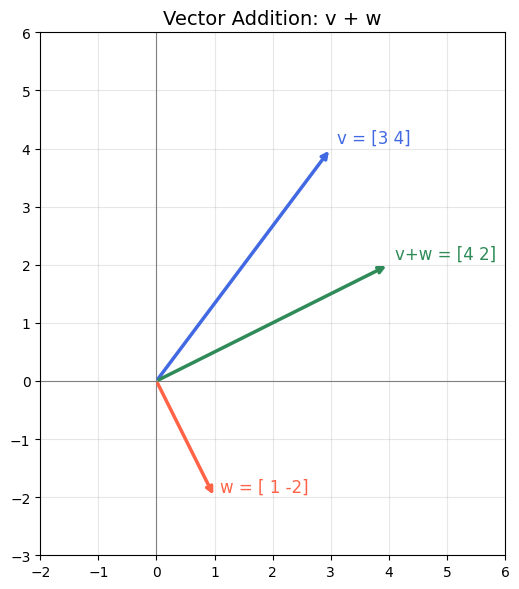

In [7]:
# ── Visualizing 2D Vectors 
print("v=", v)
print("w=", w)

fig, ax = plt.subplots(figsize=(6, 6))

origin = np.zeros(2)
vectors = {'v': (v, 'royalblue'), 'w': (w, 'tomato'), 'v+w': (v+w, 'seagreen')}

for label, (vec, color) in vectors.items():
    ax.annotate("", xy=vec, xytext=origin,
                arrowprops=dict(arrowstyle="->", color=color, lw=2.5))
    ax.text(vec[0]+0.1, vec[1]+0.1, f'{label} = {vec}', color=color, fontsize=12)

ax.set_xlim(-2, 6); ax.set_ylim(-3, 6)
ax.axhline(0, color='gray', lw=0.8); ax.axvline(0, color='gray', lw=0.8)
ax.grid(True, alpha=0.3); ax.set_aspect('equal')
ax.set_title("Vector Addition: v + w", fontsize=14)
plt.tight_layout(); plt.show()

---
<a id='3'></a>
## 3. The Dot Product

The dot product (inner product) of two vectors is:

$$\mathbf{a} \cdot \mathbf{b} = \sum_{i} a_i b_i = \|\mathbf{a}\| \|\mathbf{b}\| \cos(\theta)$$

### What it tells us:
| Result | Meaning |
|---|---|
| **Positive** | Vectors point in similar direction |
| **Zero** | Vectors are perpendicular (orthogonal) |
| **Negative** | Vectors point in opposite directions |

### 🤖 AI uses the dot product for:
- **Cosine similarity** — how similar are two word embeddings?
- **Neuron activation** — weighted sum of inputs
- **Attention scores** — in Transformer models (like ChatGPT)


In [8]:
# ── Computing Dot Products 
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

# Three equivalent ways in NumPy:
dot1 = np.dot(a, b)
dot2 = a @ b          # @ operator (most common in modern code)
dot3 = np.sum(a * b)  # manual element-wise

print(f"np.dot(a,b)  = {dot1}")
print(f"a @ b        = {dot2}")
print(f"manual sum   = {dot3}")
print(f"\na = {a}")
print(f"b = {b}")
print(f"Manual check: 1×4 + 2×5 + 3×6 = {1*4 + 2*5 + 3*6}")

np.dot(a,b)  = 32
a @ b        = 32
manual sum   = 32

a = [1 2 3]
b = [4 5 6]
Manual check: 1×4 + 2×5 + 3×6 = 32


In [9]:
# ── Cosine Similarity — the AI workhorse 
def cosine_similarity(a, b):
    """Similarity between -1 (opposite) and +1 (identical direction)."""
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

# Imagine these are word embedding vectors
king   = np.array([0.9, 0.1, 0.8, 0.2])   # made-up for illustration
queen  = np.array([0.85, 0.15, 0.75, 0.3])
car    = np.array([0.1, 0.9, 0.05, 0.8])

print("king  ↔ queen  similarity:", round(cosine_similarity(king, queen), 4))
print("king  ↔ car    similarity:", round(cosine_similarity(king, car), 4))
print("\nHigher = more similar. 'king' and 'queen' should score much higher!")

king  ↔ queen  similarity: 0.9946
king  ↔ car    similarity: 0.2566

Higher = more similar. 'king' and 'queen' should score much higher!


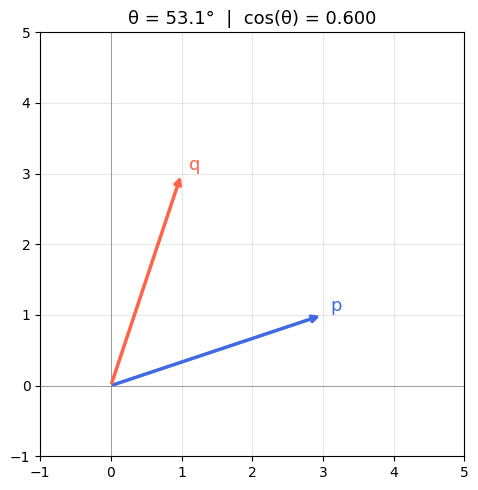

In [10]:
# ── Visualising angle θ between two vectors 
p = np.array([3, 1])
q = np.array([1, 3])

cos_theta = cosine_similarity(p, q)
theta_deg = np.degrees(np.arccos(cos_theta))

fig, ax = plt.subplots(figsize=(5,5))
for vec, color, label in [(p,'royalblue','p'), (q,'tomato','q')]:
    ax.annotate("", xy=vec, xytext=[0,0],
                arrowprops=dict(arrowstyle="->", color=color, lw=2.5))
    ax.text(vec[0]+0.1, vec[1]+0.05, label, color=color, fontsize=13)

ax.set_xlim(-1,5); ax.set_ylim(-1,5)
ax.axhline(0, color='gray', lw=0.5); ax.axvline(0, color='gray', lw=0.5)
ax.grid(True, alpha=0.3); ax.set_aspect('equal')
ax.set_title(f"θ = {theta_deg:.1f}°  |  cos(θ) = {cos_theta:.3f}", fontsize=13)
plt.tight_layout(); plt.show()


---
<a id='4'></a>
## 4. Matrices

A **matrix** is a 2D array of numbers with **m rows** and **n columns** — written as an *m × n matrix*.

$$A = \begin{bmatrix} 1 & 2 & 3 \\ 4 & 5 & 6 \end{bmatrix} \quad \text{(2 × 3 matrix)}$$

### In AI:
- A **dataset** of 1000 samples with 20 features → 1000 × 20 matrix  
- A neural network **weight layer** → matrix  
- A **grayscale image** (28×28 pixels) → 28 × 28 matrix


In [12]:
# ── Creating Matrices
A = np.array([
    [1, 2, 3],
    [4, 5, 6]
])

B = np.array([
    [7, 8, 9],
    [10, 11, 12]
])

print("A =\n", A)
print("\nShape of A:", A.shape, "→", A.shape[0], "rows,", A.shape[1], "cols")
print("\nElement at row 1, col 2  (0-indexed):", A[1, 2])
print("Second row:", A[1, :])
print("First column:", A[:, 0])

A =
 [[1 2 3]
 [4 5 6]]

Shape of A: (2, 3) → 2 rows, 3 cols

Element at row 1, col 2  (0-indexed): 6
Second row: [4 5 6]
First column: [1 4]


In [14]:
# ── Element-wise operations 
print("A + B =\n", A + B)
print("\n3 * A =\n", 3 * A)
print("\nA squared (element-wise, NOT matrix power) =\n", A ** 2)

A + B =
 [[ 8 10 12]
 [14 16 18]]

3 * A =
 [[ 3  6  9]
 [12 15 18]]

A squared (element-wise, NOT matrix power) =
 [[ 1  4  9]
 [16 25 36]]


In [10]:
# ── Transpose: flip rows ↔ columns 
print("A =\n", A, "  shape:", A.shape)
print("\nA.T (transpose) =\n", A.T, "  shape:", A.T.shape)

# Key rule: (AB)^T = B^T A^T

A =
 [[1 2 3]
 [4 5 6]]   shape: (2, 3)

A.T (transpose) =
 [[1 4]
 [2 5]
 [3 6]]   shape: (3, 2)


In [21]:
# A simple application of transpose
import seaborn as sns
import pandas as pd

# 1. Load a sample dataset from Seaborn
df = sns.load_dataset('iris')

summary = df.describe()
print("summary:\n", summary)

print("\n----------------------")
transposed_summary = df.describe().T
print("transposed_summary:\n", transposed_summary)

summary:
        sepal_length  sepal_width  petal_length  petal_width
count    150.000000   150.000000    150.000000   150.000000
mean       5.843333     3.057333      3.758000     1.199333
std        0.828066     0.435866      1.765298     0.762238
min        4.300000     2.000000      1.000000     0.100000
25%        5.100000     2.800000      1.600000     0.300000
50%        5.800000     3.000000      4.350000     1.300000
75%        6.400000     3.300000      5.100000     1.800000
max        7.900000     4.400000      6.900000     2.500000

----------------------
transposed_summary:
               count      mean       std  min  25%   50%  75%  max
sepal_length  150.0  5.843333  0.828066  4.3  5.1  5.80  6.4  7.9
sepal_width   150.0  3.057333  0.435866  2.0  2.8  3.00  3.3  4.4
petal_length  150.0  3.758000  1.765298  1.0  1.6  4.35  5.1  6.9
petal_width   150.0  1.199333  0.762238  0.1  0.3  1.30  1.8  2.5


---
<a id='5'></a>
## 5. Matrix Multiplication

Matrix multiplication is NOT element-wise. For **A (m×k)** × **B (k×n)** → result is **(m×n)**:

$$C_{ij} = \sum_{k} A_{ik} \cdot B_{kj}$$

**Rule:** Inner dimensions must match. `(m×k) @ (k×n) = (m×n)`
- Number of columns in first matrix  A = number of rows in  second matrix B

> 🧠 This is exactly how data flows through a neural network layer!


In [22]:
# ── Matrix Multiplication 
W = np.array([[1, 2],       # 3×2 weight matrix (like a neural net layer)
              [3, 4],
              [5, 6]])

x = np.array([[1],          # 2×1 input vector (column vector)
              [2]])

result = W @ x              # (3×2) @ (2×1) = (3×1)

print("W (weight matrix) =\n", W, "  shape:", W.shape)
print("\nx (input vector) =\n", x, "  shape:", x.shape)
print("\nW @ x (output) =\n", result, "  shape:", result.shape)
print("\nManual check row 0: 1×1 + 2×2 =", 1*1 + 2*2)

W (weight matrix) =
 [[1 2]
 [3 4]
 [5 6]]   shape: (3, 2)

x (input vector) =
 [[1]
 [2]]   shape: (2, 1)

W @ x (output) =
 [[ 5]
 [11]
 [17]]   shape: (3, 1)

Manual check row 0: 1×1 + 2×2 = 5


In [23]:
# ── Non-commutativity: A@B ≠ B@A 
A = np.array([[1,2],[3,4]])
B = np.array([[5,6],[7,8]])

print("A @ B =\n", A @ B)
print("\nB @ A =\n", B @ A)
print("\nAre they equal?", np.allclose(A @ B, B @ A))


A @ B =
 [[19 22]
 [43 50]]

B @ A =
 [[23 34]
 [31 46]]

Are they equal? False


In [13]:
# ── Neural Network Forward Pass — Mini Demo ───────────────────────────
np.random.seed(42)

# Simulated 1 sample with 4 features (e.g., height, weight, age, income)
x = np.array([1.5, 0.8, -0.3, 2.1])     # shape: (4,)

# Hidden layer weights: 4 inputs → 3 neurons
W1 = np.random.randn(3, 4) * 0.5
b1 = np.zeros(3)

# Output layer: 3 neurons → 1 output (regression)
W2 = np.random.randn(1, 3) * 0.5
b2 = np.zeros(1)

# ReLU activation (common in neural nets)
relu = lambda z: np.maximum(0, z)

# Forward pass
z1 = W1 @ x + b1          # (3,4)@(4,) + (3,) = (3,)
a1 = relu(z1)              # apply activation
z2 = W2 @ a1 + b2          # (1,3)@(3,) + (1,) = (1,)

print("Input x:", x)
print("Hidden layer z1 (pre-activation):", z1.round(3))
print("Hidden layer a1 (after ReLU):", a1.round(3))
print("Output z2:", z2.round(3))
print("\n✅ This is exactly one forward pass through a 2-layer neural network!")


Input x: [ 1.5  0.8 -0.3  2.1]
Hidden layer z1 (pre-activation): [ 1.819  0.3   -0.555]
Hidden layer a1 (after ReLU): [1.819 0.3   0.   ]
Output z2: [-0.067]

✅ This is exactly one forward pass through a 2-layer neural network!


---
<a id='6'></a>
## 6. Special Matrices

| Matrix | Definition | Importance |
|---|---|---|
| **Identity (I)** | 1s on diagonal, 0s elsewhere | A·I = A (like multiplying by 1) |
| **Diagonal** | Non-zero only on diagonal | Fast computation |
| **Symmetric** | A = Aᵀ | Covariance matrices, always real eigenvalues |
| **Inverse (A⁻¹)** | A·A⁻¹ = I | Solving equations |
| **Orthogonal** | AᵀA = I | Rotations, PCA eigenvectors |


In [26]:
# ── Identity Matrix 
I = np.eye(2)
print("Identity matrix I:\n", I)

A = np.array([
    [2,1],
    [5,3]
])

print("\nA @ I =\n", A @ I, "  (unchanged ✅)")


Identity matrix I:
 [[1. 0.]
 [0. 1.]]

A @ I =
 [[2. 1.]
 [5. 3.]]   (unchanged ✅)


In [ ]:
# ── Matrix Inverse 
A = np.array([[2, 1],
              [5, 3]], dtype=float)

A_inv = np.linalg.inv(A)
print("A =\n", A)
print("\nA⁻¹ =\n", A_inv)
print("\nA @ A⁻¹ =\n", (A @ A_inv).round(10), "  (≈ Identity ✅)")


A =
 [[2. 1.]
 [5. 3.]]

A⁻¹ =
 [[ 3. -1.]
 [-5.  2.]]

A @ A⁻¹ =
 [[ 1.  0.]
 [-0.  1.]]   (≈ Identity ✅)


In [ ]:
# ── Determinant — does an inverse exist? 
A_good = np.array([[2, 1], 
                   [5, 3]
])

A_bad  = np.array([[1, 2],
                   [2, 4]
])   # row 2 = 2 × row 1 (singular)

print("det(A_good) =", np.linalg.det(A_good))   # non-zero → invertible
print("det(A_bad)  =", np.linalg.det(A_bad))     # ≈ 0     → NOT invertible


det(A_good) = 1.0000000000000009
det(A_bad)  = 0.0


---
<a id='7'></a>
## 7. Solving Linear Systems

The system $A\mathbf{x} = \mathbf{b}$ represents multiple equations.

**Example:**
$$2x + y = 5$$
$$5x + 3y = 13$$

In matrix form: $A\mathbf{x} = \mathbf{b}$ where $A = \begin{bmatrix}2&1\\5&3\end{bmatrix}$, $\mathbf{b} = \begin{bmatrix}5\\13\end{bmatrix}$

Solution: $\mathbf{x} = A^{-1}\mathbf{b}$  (but use `np.linalg.solve` — it's more numerically stable)


In [18]:
# ── Solving Ax = b ────────────────────────────────────────────────────
A = np.array([[2, 1],
              [5, 3]], dtype=float)
b = np.array([5, 13], dtype=float)

# Method 1: inverse (avoid for large systems)
x_inv = np.linalg.inv(A) @ b

# Method 2: np.linalg.solve  ← preferred
x_sol = np.linalg.solve(A, b)

print("Solution x:", x_sol)
print("Verify A @ x:", A @ x_sol, "==", b, "✅")


Solution x: [2. 1.]
Verify A @ x: [ 5. 13.] == [ 5. 13.] ✅


---
<a id='8'></a>
## 🤖 8. AI Application: Images as Matrices

A grayscale image is simply a **matrix of pixel values** (0 = black, 255 = white).

Operations like **blurring** or **sharpening** are matrix operations!  
In Convolutional Neural Networks (CNNs), small *filter matrices* are slid over the image — this is matrix math at scale.


In [19]:
# ── Create a simple synthetic image 
np.random.seed(0)

# Simple 8×8 "image" — diagonal pattern
img = np.zeros((8, 8))
for i in range(8):
    img[i, i] = 200
    img[i, 7-i] = 150
    if i < 7:
        img[i, i+1] = 100

print("Image matrix (pixel values):\n", img.astype(int))


Image matrix (pixel values):
 [[200 100   0   0   0   0   0 150]
 [  0 200 100   0   0   0 150   0]
 [  0   0 200 100   0 150   0   0]
 [  0   0   0 200 100   0   0   0]
 [  0   0   0 150 200 100   0   0]
 [  0   0 150   0   0 200 100   0]
 [  0 150   0   0   0   0 200 100]
 [150   0   0   0   0   0   0 200]]


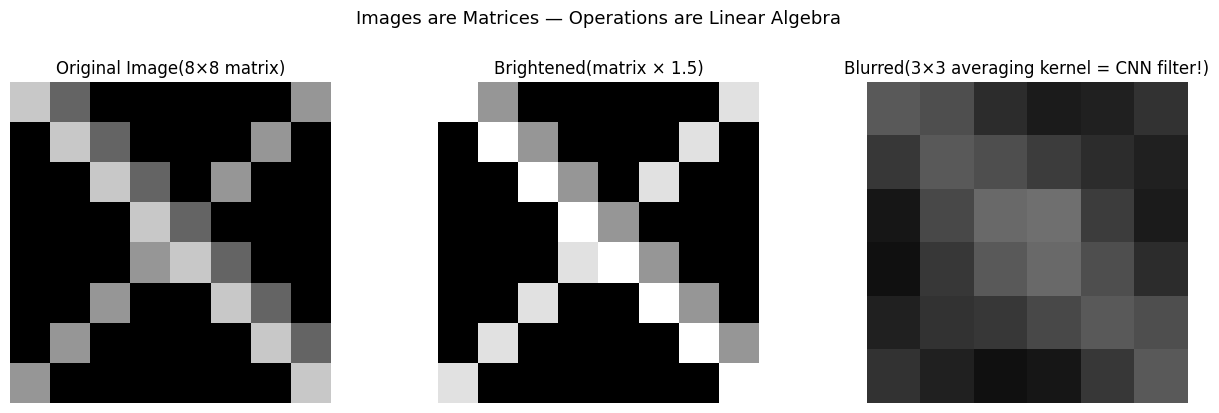


🧠 CNNs learn the optimal kernel values automatically during training!


In [23]:
# ── Visualize ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Original
axes[0].imshow(img, cmap='gray', vmin=0, vmax=255)
axes[0].set_title("Original Image(8×8 matrix)")

# Brighten = scalar multiply
bright = np.clip(img * 1.5, 0, 255)
axes[1].imshow(bright, cmap='gray', vmin=0, vmax=255)
axes[1].set_title("Brightened(matrix × 1.5)")

# Simple blur: average with transpose (symmetric smoothing)
kernel = np.ones((3,3)) / 9     # 3×3 averaging kernel (convolution filter)

# Manual 'valid' convolution for illustration
h, w = img.shape
blurred = np.zeros((h-2, w-2))
for i in range(h-2):
    for j in range(w-2):
        blurred[i,j] = np.sum(img[i:i+3, j:j+3] * kernel)

axes[2].imshow(blurred, cmap='gray', vmin=0, vmax=255)
axes[2].set_title("Blurred(3×3 averaging kernel = CNN filter!)")

for ax in axes:
    ax.axis('off')
plt.suptitle("Images are Matrices — Operations are Linear Algebra", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()
print("\n🧠 CNNs learn the optimal kernel values automatically during training!")


---
## ✅ Notebook 1 Summary

| Concept | Key Formula | NumPy function |
|---|---|---|
| Vector magnitude | $\|\mathbf{v}\| = \sqrt{\sum v_i^2}$ | `np.linalg.norm(v)` |
| Dot product | $\mathbf{a}\cdot\mathbf{b} = \sum a_i b_i$ | `a @ b` |
| Cosine similarity | $\cos\theta = \frac{\mathbf{a}\cdot\mathbf{b}}{\|\mathbf{a}\|\|\mathbf{b}\|}$ | manual formula |
| Matrix multiply | $(AB)_{ij} = \sum_k A_{ik}B_{kj}$ | `A @ B` |
| Inverse | $AA^{-1} = I$ | `np.linalg.inv(A)` |
| Solve $Ax=b$ | $x = A^{-1}b$ | `np.linalg.solve(A,b)` |

➡️ **Continue to Notebook 2: Eigenvalues, Eigenvectors & AI Applications**
